# El costo de un arreglo de trampas y su gradiente: lo que se le da a un optimizador

**Pregunta:** ¿Qué número minimiza un optimizador de gradiente conjugado para un arreglo de trampas, se puede confiar en su gradiente analítico, y cómo se ve el primer descenso junto a un lazo de proyección?

- Nivel: 1, fundamentos.
- Requisitos previos: `03-gerchberg-saxton/02-weights-for-uniformity`, que presenta el lazo ponderado M06 y las tres métricas de las trampas.
- Tiempo de lectura: unos 20 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

Un lazo de Gerchberg-Saxton nunca dice qué está minimizando: alterna dos proyecciones, y la calidad del arreglo es lo que el lazo alcance. Un optimizador funciona al revés. Uno escribe el número que dice cuán malo es un holograma y el optimizador lo baja. Este notebook escribe ese número para un arreglo de trampas, verifica la derivada en que se apoyan todos los métodos de gradiente del tema y ejecuta un primer descenso. Al terminar puedes:

- escribir el costo de un arreglo de trampas y decir qué pide cada uno de sus términos;
- verificar un gradiente analítico contra diferencias finitas y leer el gráfico que muestra si lo supera;
- ejecutar gradiente conjugado desde fases aleatorias y decir cómo es su descenso;
- decir cómo se compara el primer descenso con el lazo ponderado M06 con iguales iteraciones.

Los notebooks siguientes se apoyan en él: `05-optimization/02-the-wirtinger-gradient-and-adams-step` cambia el modelo directo, y los dos notebooks de nivel 3 del tema comparan los métodos M10 y M11 con los lazos clásicos.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg
from pipeline.model.holo.methods.optim._common import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee un caso del archivo de ejemplo `data/examples/cases.json`, escrito por la biblioteca de casos del pipeline y leído con el lector de contrato del propio pipeline.

- Propietario: este repositorio; el caso es sintético, definido por la tarea de calibración de Di Leonardo, Ianni y Ruocco (2007).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C12 (un arreglo cuadrado de 10 x 10 sobre un haz gaussiano).

In [2]:
# el caso C12 del archivo de ejemplo: el montaje óptico y las 100 trampas de la tarea de 10 x 10
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")
print("paso", rec["setup"]["pitch_um"], "um | longitud de onda", rec["setup"]["wavelength_nm"], "nm")

C12_calibration | 100 trampas | SLM 256 x 256 píxeles
paso 20 um | longitud de onda 850 nm


## Método

### Paso 1: el costo y su gradiente

Sea $V_m$ el campo en la trampa $m$ e $I_m = |V_m|^2$ la fracción de la potencia de entrada que le llega. El costo de Harte et al. (2014, ecs. 6 y 10) para trampas puntuales es

$$C_t(\phi) = \frac{\sum_m (I_m - s\,T_m)^t}{\sum_m (s\,T_m)^t}, \qquad T_m = \eta\,\frac{w_m}{\sum_k w_k},$$

donde $w_m$ son los pesos objetivo, $\eta$ la eficiencia que se le pide al objetivo, $s$ una escala fija (1 aquí) y $t$ una potencia par; $t = 2$ es el error cuadrático simple. En esta sola línea hay dos cosas que un lazo de proyección deja implícitas. La suma de los objetivos es $\eta$, de modo que el costo pide una potencia total además de trampas iguales. Y el denominador hace que el valor no dependa de la escala.

El gradiente respecto de la fase de cada píxel sale de la regla de la cadena a través de la transformada de Fourier. Para una pérdida real $L(I)$ el gradiente de Wirtinger respecto del campo complejo es $G = L'(I)\,V$ (Chakravarthula et al., 2019), y llevarlo atrás por el adjunto de la propagación da $\partial L / \partial \phi_j = 2\,\mathrm{Re}\,(i f_j\,\overline{(\mathrm{Op}^H G)_j})$, con $f_j = A_j e^{i\phi_j}$ el campo en el SLM. En el pipeline el costo es la clase `TrapCost`, una clase pública del módulo compartido de optimización, y `value_grad` devuelve el valor y el gradiente completo, un número por píxel, con una transformada directa y una adjunta.

La celda siguiente construye el costo de la tarea de 10 x 10 en un patrón de fase aleatorio y lee la pendiente del costo a lo largo de una dirección unitaria aleatoria.

In [3]:
# el costo explícito de la tarea y su gradiente analítico en un patrón de fase aleatorio
cost = TrapCost(setup, target.traps, None, t=2, efficiency=0.9)
rng = Rng(5)
phi0 = rng.phases(setup.n_pix**2).reshape(setup.n_pix, setup.n_pix)
value, grad, _ = cost.value_grad(phi0)
direction = rng.normal_array(setup.n_pix**2).reshape(phi0.shape)
direction /= np.linalg.norm(direction)
slope = float(np.sum(grad * direction))
print(f"costo en la fase aleatoria: {value:.6f}")
print(f"pendiente analítica en una dirección unitaria aleatoria: {slope:.6e}")

costo en la fase aleatoria: 0.996880
pendiente analítica en una dirección unitaria aleatoria: -2.124944e-08


Un gradiente analítico vale lo que vale su derivación, así que se verifica antes de confiar en él. Una diferencia central $(C(\phi + h d) - C(\phi - h d)) / 2h$ a lo largo de la misma dirección $d$ debe reproducir la pendiente analítica $g \cdot d$. El paso $h$ tiene una ventana: si es muy grande la diferencia no ve la curvatura del costo, y si es muy pequeño la resta de dos costos casi iguales pierde cifras. La celda barre $h$ en seis décadas.

In [4]:
# diferencias centrales del mismo costo en la misma dirección, con pasos de 1e-1 a 1e-6
steps = 10.0 ** -np.arange(1, 7)
rel_err = []
for h in steps:
    up = cost.value_grad(phi0 + h * direction)[0]
    down = cost.value_grad(phi0 - h * direction)[0]
    rel_err.append(abs((up - down) / (2 * h) - slope) / abs(slope))
for h, err in zip(steps, rel_err):
    print(f"paso {h:.0e}: error relativo de la pendiente {err:.2e}")

paso 1e-01: error relativo de la pendiente 1.24e-05
paso 1e-02: error relativo de la pendiente 5.80e-07
paso 1e-03: error relativo de la pendiente 8.04e-06
paso 1e-04: error relativo de la pendiente 3.68e-05
paso 1e-05: error relativo de la pendiente 2.72e-04
paso 1e-06: error relativo de la pendiente 2.08e-03


Los errores impresos se leen mejor como una curva de error frente al paso.

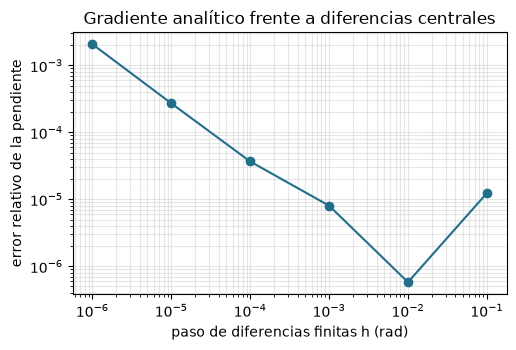

In [5]:
# el error de la pendiente por diferencias finitas frente al tamaño del paso
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.loglog(steps, rel_err, "o-", color="#1f6f8b")
ax.set_xlabel("paso de diferencias finitas h (rad)")
ax.set_ylabel("error relativo de la pendiente")
ax.set_title("Gradiente analítico frente a diferencias centrales")
ax.grid(True, which="both", alpha=0.3)
plt.show()

La curva es una V. A la derecha el error baja al achicar el paso, porque el error de truncamiento de una diferencia central escala con $h^2$; a la izquierda vuelve a subir como $1/h$, que es la pérdida de cifras en la resta. El mínimo, cerca de $h = 10^{-2}$ rad, es un error relativo de $5{,}8 \times 10^{-7}$: el gradiente analítico coincide con la pendiente numérica en seis cifras, de modo que la derivación y su implementación son correctas. El gráfico no dice que el gradiente sea correcto en cada píxel, solo a lo largo de esta dirección y en este patrón de fase; las pruebas del propio pipeline repiten la verificación en objetivos de trampas y de formas, y una verificación en unas pocas direcciones aleatorias es el estándar habitual. También indica el paso que conviene usar si alguna vez verificas un gradiente propio: no el más pequeño, sino uno en el centro de la V.

### Paso 2: un primer descenso

M10 ejecuta gradiente conjugado de Fletcher-Reeves con búsqueda de línea de Wolfe fuerte sobre este costo, partiendo de fases aleatorias sorteadas con el generador con semilla. El presupuesto por defecto del registro es de 30 iteraciones, así que la primera celda ejecuta eso e imprime dónde está el descenso.

In [6]:
# el mismo costo con el presupuesto por defecto del registro: gradiente conjugado durante 30 iteraciones
# desde fases aleatorias
res_cg30 = m10_cg.run(setup, target, budget=Budget(30), rng=Rng(1))
last = res_cg30.history[-1]
print(f"tras 30 iteraciones: costo {last['cost']:.4f}  eficiencia {last['efficiency']:.3f}  "
      f"desv. rel. {last['rel_std']:.2f} %")

tras 30 iteraciones: costo 0.4906  eficiencia 0.278  desv. rel. 37.27 %


Tras 30 iteraciones el costo sigue en 0,49 y el arreglo está lejos de ser igual, de modo que el presupuesto que le sirve al GS ponderado no le sirve a este método. La celda ejecuta 300 iteraciones, con una búsqueda de línea de unas pocas evaluaciones cada una, e imprime el costo, la eficiencia y la desviación estándar relativa de $I_m / w_m$ en seis de ellas.

In [7]:
# gradiente conjugado sobre el costo: 300 iteraciones desde una fase aleatoria, eficiencia objetivo 0.9
res_cg = m10_cg.run(setup, target, budget=Budget(300), rng=Rng(1))
cg = res_cg.history
costs = np.array([h["cost"] for h in cg])
for k in (0, 9, 49, 99, 199, 299):
    h = cg[k]
    print(f"iteración {h['iteration']:3d}: costo {h['cost']:.4f}  "
          f"eficiencia {h['efficiency']:.3f}  desv. rel. {h['rel_std']:.2f} %")
print(f"mayor cambio del costo entre dos iteraciones: {np.max(np.diff(costs)):.2e}")

iteración   1: costo 0.7220  eficiencia 0.148  desv. rel. 93.73 %
iteración  10: costo 0.6180  eficiencia 0.202  desv. rel. 57.55 %
iteración  50: costo 0.4062  eficiencia 0.333  desv. rel. 26.87 %
iteración 100: costo 0.2618  eficiencia 0.442  desv. rel. 11.50 %
iteración 200: costo 0.0950  eficiencia 0.624  desv. rel. 5.10 %
iteración 300: costo 0.0222  eficiencia 0.767  desv. rel. 2.08 %
mayor cambio del costo entre dos iteraciones: -3.06e-04


El costo bajó en cada paso: el mayor cambio entre dos iteraciones consecutivas es negativo, de modo que nunca subió. Eso es lo primero que aporta un costo explícito, un descenso que se puede vigilar. Sin embargo, la desviación estándar relativa sigue en 2 por ciento tras 300 iteraciones y la eficiencia sigue subiendo. Para tener una escala, ejecuta el lazo de Gerchberg-Saxton ponderado M06 (Di Leonardo et al., 2007) sobre la misma tarea y la misma semilla durante 100 iteraciones, y evalúa su fase final con el costo de arriba, de modo que ambos métodos se juzguen con el mismo número.

In [8]:
# Gerchberg-Saxton ponderado sobre la misma tarea y semilla, 100 iteraciones, evaluado con el mismo costo
res_gsw = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
gsw = res_gsw.history
for k in (0, 9, 29, 99):
    h = gsw[k]
    print(f"iteración {h['iteration']:3d}: eficiencia {h['efficiency']:.3f}  "
          f"desv. rel. {h['rel_std']:.2f} %")
print(f"costo de la fase de GS ponderado tras 100 iteraciones: {cost.value_grad(res_gsw.phi)[0]:.4f}")
print(f"costo de la fase de CG tras 300 iteraciones: {cost.value_grad(res_cg.phi)[0]:.4f}")

iteración   1: eficiencia 0.755  desv. rel. 26.15 %
iteración  10: eficiencia 0.789  desv. rel. 4.23 %
iteración  30: eficiencia 0.797  desv. rel. 0.92 %
iteración 100: eficiencia 0.807  desv. rel. 0.24 %
costo de la fase de GS ponderado tras 100 iteraciones: 0.0107
costo de la fase de CG tras 300 iteraciones: 0.0222


Ambos historiales se grafican contra la iteración. La iteración es la unidad de presupuesto del registro, pero no es la misma cantidad de trabajo para los dos métodos: una iteración de CG incluye una búsqueda de línea con varias evaluaciones del costo, mientras que una de GS ponderado es una transformada directa y una inversa.

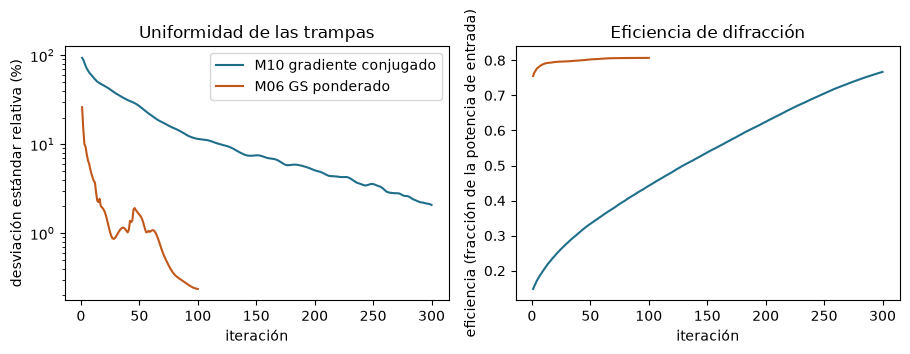

In [9]:
# desviación estándar relativa y eficiencia de ambos métodos frente a la iteración
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5))
its_cg, its_gsw = [h["iteration"] for h in cg], [h["iteration"] for h in gsw]
a.semilogy(its_cg, [h["rel_std"] for h in cg], color="#1f6f8b", label="M10 gradiente conjugado")
a.semilogy(its_gsw, [h["rel_std"] for h in gsw], color="#c2571a", label="M06 GS ponderado")
a.set_xlabel("iteración")
a.set_ylabel("desviación estándar relativa (%)")
a.set_title("Uniformidad de las trampas")
a.legend()
b.plot(its_cg, [h["efficiency"] for h in cg], color="#1f6f8b")
b.plot(its_gsw, [h["efficiency"] for h in gsw], color="#c2571a")
b.set_xlabel("iteración")
b.set_ylabel("eficiencia (fracción de la potencia de entrada)")
b.set_title("Eficiencia de difracción")
plt.tight_layout()
plt.show()

En uniformidad los lazos de la familia de Gerchberg-Saxton van muy adelante: M06 baja de 1 por ciento tras 30 iteraciones y llega a 0,24 por ciento tras 100, mientras que CG desde fases aleatorias necesita las 300 iteraciones para llegar a 2,08 por ciento. El panel de eficiencia muestra por qué. CG parte de fases aleatorias y tiene 15 por ciento de eficiencia tras su primera iteración, y el costo solo puede reducir la diferencia con la eficiencia objetivo subiendo la luz en las trampas, lo que hace de a poco; M06 parte de un holograma de superposición y tiene 75 por ciento tras su primera iteración. Las curvas no muestran el costo por iteración ni la calidad final que CG alcanzaría con miles de iteraciones, que Harte et al. informan como 0,58 por ciento en una red cuadrada tras 4000; muestran que, en esta tarea de trampas puntuales, el lazo de proyección es la herramienta mucho más rápida. La fase de GS ponderado también tiene el menor costo de los dos con estos presupuestos.

## Resultados

**Respuesta:** El optimizador minimiza $C_2$, el desajuste cuadrático entre las intensidades de las trampas y un objetivo de trampas iguales con eficiencia total de 0,9, y su gradiente analítico es confiable: coincide con las diferencias centrales con un error relativo de 5,80e-07 en el mejor paso, con la curva de error en V que predicen el truncamiento y el redondeo. El primer descenso es monótono, siendo -3,06e-04 el mayor cambio del costo entre dos iteraciones, pero es lento desde fases aleatorias: 30 iteraciones dejan el costo en 0,4906, y 300 llegan a una desviación estándar relativa de 2,08 por ciento. El GS ponderado (M06) está en 0,92 por ciento tras 30 iteraciones y en 0,24 por ciento tras 100, de modo que en esta tarea de trampas puntuales el lazo de proyección es la herramienta mucho más rápida, y su fase tiene además el menor costo de los dos.

Lo que el notebook no muestra es lo que compra el costo explícito a cambio de esa velocidad; el notebook de nivel 3 `05-optimization/03-conjugate-gradient-against-weighted-gs` lo mide.

## Resumen

- El costo $C_t$ de Harte et al. escribe toda la tarea como un número: trampas iguales y una potencia total declarada.
- Su gradiente sale de dos transformadas de Fourier y coincide con las diferencias centrales en 5,8e-07; la curva de error en V indica el paso que conviene usar en una verificación así.
- El gradiente conjugado baja el costo en cada iteración, pero desde fases aleatorias necesita cientos de iteraciones donde el GS ponderado necesita decenas.
- Los notebooks siguientes conservan este costo y cambian lo que se hace con él.

## Referencias

- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539